In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
# Note: We use '../data/spam.csv' because the notebook is inside the 'notebooks' folder.
# We use encoding='latin-1' because the standard UCI SMS dataset has some special characters.
df = pd.read_csv('../data/spam.csv', encoding='latin-1')

# Display the first 5 rows
df.head()

Matplotlib is building the font cache; this may take a moment.


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
# 1. Drop the useless 'Unnamed' columns
df = df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'])

# 2. Rename 'v1' to 'label' and 'v2' to 'message' for professional clarity
df = df.rename(columns={'v1': 'label', 'v2': 'message'})

# 3. Display the first 5 rows to verify the cleanup
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


--- Class Distribution ---
label
ham     4825
spam     747
Name: count, dtype: int64

--- Percentage ---
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


C:\Users\M Saifullah\AppData\Local\Temp\ipykernel_13936\1978463826.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


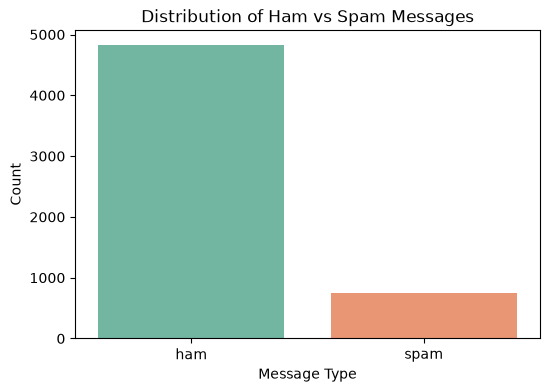

In [4]:
# Count how many ham and spam messages we have
print("--- Class Distribution ---")
print(df['label'].value_counts())

# Calculate the percentage
print("\n--- Percentage ---")
print(df['label'].value_counts(normalize=True) * 100)

# Visualize it
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Distribution of Ham vs Spam Messages')
plt.xlabel('Message Type')
plt.ylabel('Count')
plt.show()

In [5]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

# Download necessary NLTK data files (only runs once)
nltk.download('stopwords')
nltk.download('punkt')

# Initialize the stemmer and the list of English stop words
ps = PorterStemmer()
stop_words = set(stopwords.words('english'))

def clean_text(message):
    # 1. Remove special characters and numbers (keep only a-z and A-Z)
    message = re.sub(r'[^a-zA-Z]', ' ', message)
    
    # 2. Convert to lowercase
    message = message.lower()
    
    # 3. Tokenize (split the sentence into individual words)
    words = nltk.word_tokenize(message)
    
    # 4. Remove stop words and apply stemming
    cleaned_words = []
    for word in words:
        if word not in stop_words:
            # Stemming reduces words to their root form
            cleaned_words.append(ps.stem(word))
            
    # 5. Join the cleaned words back into a single string
    return " ".join(cleaned_words)

[nltk_data] Downloading package stopwords to C:\Users\M
[nltk_data]     Saifullah\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt to C:\Users\M
[nltk_data]     Saifullah\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\M
[nltk_data]     Saifullah\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


In [6]:
# Apply the clean_text function to the 'message' column and create a new column 'cleaned_message'
df['cleaned_message'] = df['message'].apply(clean_text)

# Let's compare the original vs the cleaned text side-by-side
print("--- ORIGINAL TEXT ---")
print(df['message'].iloc[0])
print("\n--- CLEANED TEXT ---")
print(df['cleaned_message'].iloc[0])

# Show the first 5 rows of the updated dataframe
df[['label', 'cleaned_message']].head()

--- ORIGINAL TEXT ---
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

--- CLEANED TEXT ---
go jurong point crazi avail bugi n great world la e buffet cine got amor wat


,label,cleaned_message
0,ham,go jurong point crazi avail bugi n great world...
1,ham,ok lar joke wif u oni
2,spam,free entri wkli comp win fa cup final tkt st m...
3,ham,u dun say earli hor u c alreadi say
4,ham,nah think goe usf live around though


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Define Features (X) and Target (y)
X = df['cleaned_message']
y = df['label']

# 2. Split the data: 80% for training, 20% for testing
# We use stratify=y to ensure the 86/14 ham/spam ratio is maintained in both sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} messages")
print(f"Testing set size: {X_test.shape[0]} messages")

# 3. Initialize the TF-IDF Vectorizer
# max_df=0.95 ignores words that appear in more than 95% of documents (too common)
# min_df=2 ignores words that appear in fewer than 2 documents (too rare/typos)
vectorizer = TfidfVectorizer(max_df=0.95, min_df=2)

# 4. Fit the vectorizer on training data and transform it
# (We ONLY fit on training data to prevent "data leakage" from the test set)
X_train_vectorized = vectorizer.fit_transform(X_train)

# 5. Transform the test data (do NOT fit, only transform)
X_test_vectorized = vectorizer.transform(X_test)

print(f"\nVectorized Training Data Shape: {X_train_vectorized.shape}")
print(f"Vectorized Testing Data Shape: {X_test_vectorized.shape}")

Training set size: 4457 messages
Testing set size: 1115 messages

Vectorized Training Data Shape: (4457, 2776)
Vectorized Testing Data Shape: (1115, 2776)


In [8]:
# Get the feature names (the unique words the vectorizer learned)
feature_names = vectorizer.get_feature_names_out()

print(f"Total unique words (features) learned: {len(feature_names)}")
print("\nFirst 20 words in the vocabulary:")
print(feature_names[:20])

Total unique words (features) learned: 2776

First 20 words in the vocabulary:
['aathi' 'abi' 'abil' 'abiola' 'abl' 'abt' 'abta' 'aburo' 'ac' 'acc'
 'accept' 'access' 'accid' 'accident' 'accomod' 'accordingli' 'account'
 'ach' 'aco' 'across']


In [9]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Initialize the model
model = MultinomialNB()

# 2. Train (fit) the model on the vectorized training data
model.fit(X_train_vectorized, y_train)

# 3. Make predictions on the vectorized testing data
y_pred = model.predict(X_test_vectorized)

print("Model training complete!")

Model training complete!


--- Classification Report ---
              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       966
        spam       0.99      0.81      0.89       149

    accuracy                           0.97      1115
   macro avg       0.98      0.91      0.94      1115
weighted avg       0.97      0.97      0.97      1115



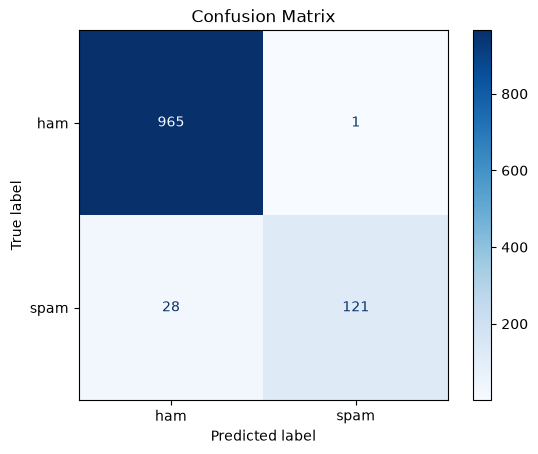

In [10]:
# 1. Print the Classification Report
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 2. Generate and display the Confusion Matrix
cm = confusion_matrix(y_test, y_test, labels=model.classes_)
# Note: The correct syntax is confusion_matrix(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()